<a href="https://colab.research.google.com/github/Decoy-walk/GDS3D/blob/master/2026_50291_3_Week3_DL_Assignment.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 3: Deep Learning

*Practical AI Design and Ethics*

## How to use this notebook

Last week, you built a hiring model from a table of numbers that someone had already chosen: years of experience, test score, referral. Real recruiting systems often skip that step and read the text itself. This week, a **neural network** reads real professional biographies and decides for itself which words matter.

This notebook walks through the same **machine learning lifecycle** as last week:
* problem formulation
* data collection
* data pre-processing and cleaning
* model and architecture selection
* training
* model evaluation
* deployment

🟢 **No coding experience:** Just run every cell in order (click a cell, press `Shift+Enter`, move to the next).

* Where you see `# ✏️ FILL IN`, pick one of the suggested options from the comment above it and re-run the cell.

* Most of your grade comes from the **written reflection questions** marked with `✏️ QUESTION`, not from writing code.

* Where you see `✏️ TINKER` you can try using a different value to see how it changes the outcome (optional).

🔵 (Optional) **Have some coding experience?** The network in this notebook averages all the word vectors in a bio, so it ignores word order. Try replacing the `GlobalAveragePooling1D()` layer in `build_model` with a layer that reads the bio in order:

```
keras.layers.Bidirectional(keras.layers.LSTM(16))
```

Does the gender gap get bigger, smaller, or stay the same?

**Before you submit**, you'll be asked to note which parts (if any) you used an AI tool like ChatGPT/Claude/Copilot to write or fix, and how confident you are in the parts you didn't write yourself.

> **Hint:** cells in Colab run top to bottom. If you skip around, re-run things out of order, or change one of the tinkering widgets below without re-running the cells after it, you may get confusing or stale results. If that happens, try "Runtime > Restart and run all." No GPU is needed: the default CPU runtime is fine.

## Learning objectives

By the end of this notebook you should be able to:

- Explain how a neural network turns raw text into a prediction
- Train a small neural network and read its training curves
- Show how a model can learn a gender shortcut from data that is accurate but imbalanced
- Explain why deleting obviously gendered words doesn't remove bias

---
## 1. Problem Formulation

**The task:** a recruiting platform wants to tag people's profiles automatically, so it can show them relevant job ads. We'll build a model that reads a short professional biography and predicts whether the person is a **surgeon**.

**Data:** real biographies collected from the web, from the *Bias in Bios* dataset (De-Arteaga et al., 2019).

**One important difference from last week:** the hiring labels in Week 2 were *past decisions*. Here, the labels are people's *actual jobs*, extracted from the bio.

`✏️ QUESTION` **If the labels are correct, can the model still be biased? How?**

Yes. The labels are correct, but the data is imbalanced: most surgeons in the dataset are men, and most nurses are women. Because the network is trained to reduce prediction error through backpropagation (Rumelhart et al., 1986), it may learn that words like “he” or “his” are useful signals for “surgeon,” even though they say nothing about the job.

As a result, the model may recognize women surgeons less reliably. Correct labels can still reflect an unequal distribution, and the model may learn that pattern as a shortcut.

---
## Setup

In [43]:
import os, re, time, textwrap, subprocess, sys
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"   # hide TensorFlow's startup messages

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from cycler import cycler
from IPython.display import display, HTML as show_html

import keras
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score
from ipywidgets import interact, IntSlider, FloatSlider, Textarea, Dropdown, Layout

try:
    from datasets import load_dataset
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "datasets"], check=True)
    from datasets import load_dataset

SEED = 42
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)
print("Setup complete.")

THEME = {
    "bg":     "#FAF8F6",  # slide background
    "text":   "#221D22",  # slide body text
    "plum":   "#3F2A3A",  # dark accent
    "mauve":  "#B49AA3",  # light accent
    "bronze": "#8A6D3B",
    "sage":   "#445341",
    "purple": "#7E4570",
    "teal":   "#0097A7",
}
PALETTE = [THEME["plum"], THEME["mauve"], THEME["bronze"], THEME["sage"], THEME["purple"], THEME["teal"]]

plt.rcParams.update({
    "figure.facecolor": THEME["bg"],
    "axes.facecolor": THEME["bg"],
    "savefig.facecolor": THEME["bg"],
    "axes.edgecolor": THEME["text"],
    "axes.labelcolor": THEME["text"],
    "text.color": THEME["text"],
    "xtick.color": THEME["text"],
    "ytick.color": THEME["text"],
    "axes.prop_cycle": cycler(color=PALETTE),
    "font.family": "sans-serif",
    "font.sans-serif": ["Helvetica Neue", "Helvetica", "Arial", "DejaVu Sans"],
    "axes.titleweight": "bold",
})
print("Theme applied.")

Setup complete.
Theme applied.


---
## 2. Data Collection

The dataset contains about 257,000 biographies from the web, covering 28 professions. To make the task harder, the first sentence of each bio has been removed, because it usually states the job directly ("Dr. X is a surgeon at...").

Two things to know about how the dataset was built:
* The **occupation** comes from how people described themselves in that first sentence.
* The **gender** was inferred from the pronouns in the bio (*he* or *she*), so it only has two values. People who use other pronouns are not in the dataset.

The next cell downloads the data (about 65 MB). It takes a minute.

In [44]:
PROFESSIONS = [
    "accountant", "architect", "attorney", "chiropractor", "comedian", "composer", "dentist",
    "dietitian", "dj", "filmmaker", "interior_designer", "journalist", "model", "nurse",
    "painter", "paralegal", "pastor", "personal_trainer", "photographer", "physician", "poet",
    "professor", "psychologist", "rapper", "software_engineer", "surgeon", "teacher", "yoga_teacher",
]

raw = load_dataset("LabHC/bias_in_bios", split="train").to_pandas()
raw = raw.rename(columns={"hard_text": "bio"})
raw["profession"] = raw["profession"].map(dict(enumerate(PROFESSIONS)))
raw["gender"] = raw["gender"].map({0: "Male", 1: "Female"})

print(f"{len(raw):,} biographies loaded.")
raw.head()

257,478 biographies loaded.


,bio,profession,gender
0,He is also the project lead of and major contr...,professor,Male
1,"She is able to assess, diagnose and treat mino...",nurse,Female
2,"Prior to law school, Brittni graduated magna c...",attorney,Female
3,He regularly contributes to India’s First Onli...,journalist,Male
4,He completed his medical degree at Northwester...,professor,Male


Let's read a few of them.

`✏️ TINKER` Every time you re-run the cell, you get a different bio.

In [45]:
for _, row in raw.sample(4).iterrows():
    print(f"[{row['profession']}, {row['gender']}]")
    print(textwrap.fill(row["bio"], 100))
    print()

[physician, Female]
Ms. Crosby practices medicine in Augusta, GA and specializes in Endocrinology, Diabetes &
Metabolism. Ms. Crosby is affiliated with University Hospital.

[nurse, Female]
She graduated with honors in 2010. Having more than 6 years of diverse experiences, especially in
NURSE PRACTITIONER, Denise A Sample affiliates with no hospital, and cooperates with other doctors
and specialists in many medical groups including Unc Physicians Network, LLC, American Current Care
Of North Carolina Pc. Call Denise A Sample on phone number (919) 261-8760 for more information and
advises or to book an appointment.

[psychologist, Female]
Her areas of expertise include adoption issues, depression, and behavior therapy. Dr. Sullivan
honors Blue Shield, Anthem, and Blue Cross/Blue Shield insurance. New patients are welcome to
contact her office for an appointment.

[professor, Female]
She received her B.A. at Yale University and Ph.D. in Sociology at the University of California Los
Angele

`✏️ QUESTION` **These bios were collected from public websites. Some include names, phone numbers, or email addresses. Is it acceptable to use them to train a model, considering they chose to share this information online?**

Not necessarily. People shared their bios to present themselves to patients or employers, not to train AI models, so being public does not mean they agreed to every use.

The data also includes names and contact details that could be exposed or linked to other information, and people cannot correct how they were labeled, such as their inferred gender. Using it may be acceptable for research if personal details are removed, the purpose is limited, and people can opt out.



> Now let's see who is in the data. For each profession, what share of the bios belong to women?

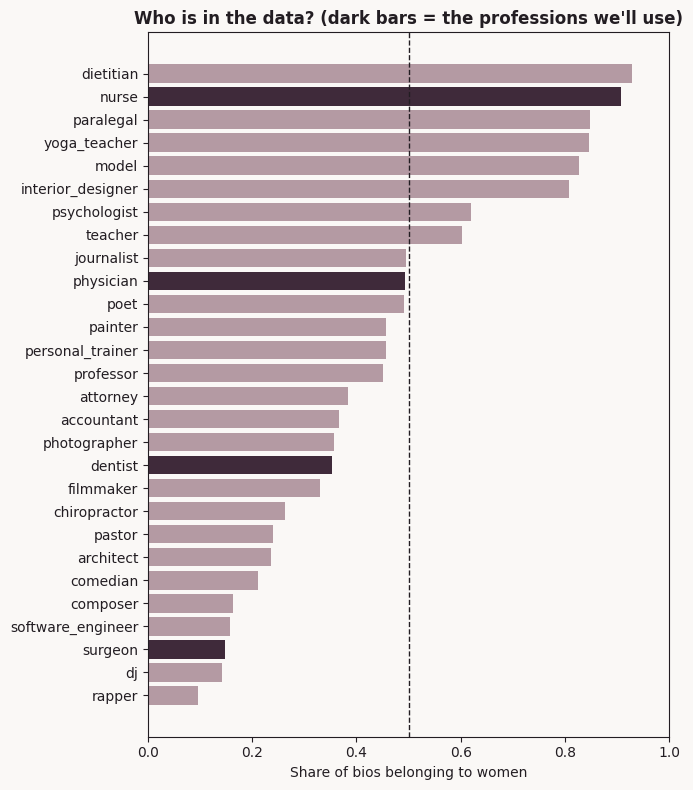

In [46]:
share_women = (raw.groupby("profession")["gender"].apply(lambda g: (g == "Female").mean())
                  .sort_values())
medical = ["surgeon", "physician", "nurse", "dentist"]
colors = [THEME["plum"] if p in medical else THEME["mauve"] for p in share_women.index]

plt.figure(figsize=(7, 8))
plt.barh(share_women.index, share_women.values, color=colors)
plt.axvline(0.5, linestyle="--", color=THEME["text"], linewidth=1)
plt.xlim(0, 1)
plt.xlabel("Share of bios belonging to women")
plt.title("Who is in the data? (dark bars = the professions we'll use)")
plt.tight_layout()
plt.show()

`✏️ QUESTION` **Look at surgeons and nurses. What do you expect a model to learn from data like this, even though every label is correct?**

In this data, only about 15% of surgeons are women, while about 90% of nurses are women.Even though every label is correct, I expect the model to learn this imbalance as a shortcut: words linked to women, such as “she” and “her,” may push a bio away from “surgeon” and toward other medical professions.

As a result, the model may recognize women surgeons less reliably than men surgeons, and men nurses less reliably than women nurses. The model would be reflecting the current gender distribution of these professions rather than the skills described in the bio.




`✏️ QUESTION` **Which words in a biography (apart from pronouns) could reveal someone's gender, directly or indirectly?**

Direactly: itles such as Mr, Ms, and Mrs; first names; and family roles such as mother, father, wife, or husband.

Indirectly: words linked to organizations or activities that are more common for one gender, such as “women's college,” “sorority,” or “fraternity,” and medical specialties that are unevenly distributed by gender, such as obstetrics, breast cancer, or pediatrics compared with orthopedics or sports medicine.

---
## 3. Data Pre-processing and Cleaning

We'll focus on four medical professions: surgeons, physicians, nurses, and dentists. The model's job is to pick out the **surgeons** among them. This makes the task realistic: the model has to tell apart people who all work in medicine, with similar vocabulary.

In [47]:
TARGET = "surgeon"   # ✏️ FILL IN: "surgeon" (default) or "nurse"
POOL = ["surgeon", "physician", "nurse", "dentist"]
n = 25000            # ✏️ TINKER: fewer bios = faster training, but noisier results

medical_bios = raw[raw["profession"].isin(POOL)]
df = medical_bios.sample(min(n, len(medical_bios)), random_state=SEED).reset_index(drop=True)
df["label"] = (df["profession"] == TARGET).astype(int)   # 1 = TARGET, 0 = any other medical profession

print(f"{len(df):,} bios. {df['label'].mean():.1%} of them are {TARGET}s.\n")
print("Bios by profession and gender:")
display(pd.crosstab(df["profession"], df["gender"], margins=True))

25,000 bios. 15.4% of them are surgeons.

Bios by profession and gender:


gender,Female,Male,All
profession,,,
dentist,1472,2686,4158
nurse,4848,473,5321
physician,5787,5875,11662
surgeon,578,3281,3859
All,12685,12315,25000


As last week, we split the data three ways: the model **learns** from the training set, we **make decisions** with the validation set, and the test set stays locked away until one final check at the end.

In [48]:
def as_text(series):
    # Keras expects text as a plain array of strings
    return series.astype(str).to_numpy(dtype=object)

train_df, test_df = train_test_split(df, test_size=0.2, random_state=SEED, stratify=df["label"])
train_df, val_df = train_test_split(train_df, test_size=0.2, random_state=SEED, stratify=train_df["label"])

X_train, y_train = as_text(train_df["bio"]), train_df["label"].to_numpy()
X_val, y_val = as_text(val_df["bio"]), val_df["label"].to_numpy()
X_test, y_test = as_text(test_df["bio"]), test_df["label"].to_numpy()

print(f"Training on {len(X_train):,} bios, validating on {len(X_val):,}, testing on {len(X_test):,}.")

Training on 16,000 bios, validating on 4,000, testing on 5,000.


---
## 4. Representation: from words to numbers

Last week, *you* chose the features. A neural network works from the raw text, in two steps:

1. **Tokenisation:** each word gets an ID number from a vocabulary. The vocabulary is built from the 10,000 most common words in the training bios.
2. **Embedding:** each ID is turned into a list of 16 numbers, called a **vector**. These numbers start random and are learned during training, so words the model uses in similar ways end up with similar vectors.

Let's see step 1 on a short sentence.

In [49]:
VOCAB_SIZE = 10000
MAX_LEN = 150   # longer bios are cut off after 150 words

vectorizer = keras.layers.TextVectorization(max_tokens=VOCAB_SIZE, output_sequence_length=MAX_LEN)
vectorizer.adapt(X_train)   # build the vocabulary from TRAINING bios only
vocab = vectorizer.get_vocabulary()

example = "She completed her surgical residency in Boston."   # ✏️ TINKER: try your own sentence
ids = vectorizer(np.array([example], dtype=object)).numpy()[0]
ids = ids[ids != 0]   # drop the padding
display(pd.DataFrame({"word": [vocab[i] for i in ids], "ID": ids}).set_index("word").T)

word,she,completed,her,surgical,residency,in,boston
ID,13,43,29,189,41,3,318


`✏️ QUESTION` **Capital letters and punctuation are removed before tokenisation. What information could be lost this way? Can you think of a case where it matters?**

Removing capitals and punctuation can erase the difference between names and ordinary words, and change some abbreviations and titles.
In the example sentence, “She” became “she” and “Boston.” became “boston,” so the model cannot tell a place name from an ordinary word. Similarly, “Rose” (a name) and “rose” would become the same, and “US” (the country) would become “us.”

Abbreviations like “Dr.” and “M.D.” would lose their periods, and “OB/GYN” may be split. This matters in medical bios because titles and degrees are strong signals of profession, and names can reveal gender.

Losing these distinctions may cause the model to miss useful job information or confuse unrelated words.

---
## 5. Model Selection: a small neural network

Our network has five steps, from text to prediction:

`bio → word IDs → word vectors → average of all the vectors → hidden layer (16 neurons) → probability of "surgeon"`

## How building a model works

```python
def build_model(hidden_units=16, dropout=0.0, embedding_dim=16):
```
**Creates the model:** Sets the number of learning units, dropout rate, and word representation size.

```python
model = keras.Sequential([
```
**Sequential model:** Processes information one layer at a time.

```python
keras.Input(shape=(1,), dtype="string"), vectorizer,
```
**Input:** Accepts text and converts words into numerical IDs.

```python
keras.layers.Embedding(VOCAB_SIZE, embedding_dim, mask_zero=True),
```
**Embedding:** Converts word IDs into numerical representations the model can learn from.

```python
keras.layers.GlobalAveragePooling1D(),
```
**Pooling:** Averages the word representations into one overall text representation.

```python
keras.layers.Dropout(dropout),
```
**Dropout:** Randomly switches off some values during training to help prevent overfitting.

```python
keras.layers.Dense(hidden_units, activation="relu"),
```
**Hidden layer:** Learns patterns in the text that help with prediction.

```python
keras.layers.Dense(1, activation="sigmoid"),
```
**Output layer:** Predicts a probability between 0 and 1 for the target category.

```python
model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
```
**Compilation:** Defines how the model learns and measures its accuracy.

```python
return model
```
**Return:** Gives us the completed model, ready to be trained.

### In short
**Text → Word IDs → Word representations → Learn patterns → Predict a category**

In [50]:
def build_model(hidden_units=16, dropout=0.0, embedding_dim=16):
    model = keras.Sequential([
        keras.Input(shape=(1,), dtype="string"), vectorizer,                 # text -> word IDs
        keras.layers.Embedding(VOCAB_SIZE, embedding_dim, mask_zero=True),   # word IDs -> vectors
        keras.layers.GlobalAveragePooling1D(),                               # average the word vectors
        keras.layers.Dropout(dropout),                                       # randomly switch off some inputs while training
        keras.layers.Dense(hidden_units, activation="relu"),                 # hidden layer
        keras.layers.Dense(1, activation="sigmoid"),                         # probability of TARGET
    ])
    model.compile(optimizer="adam", loss="binary_crossentropy", metrics=["accuracy"])
    return model

keras.utils.set_random_seed(SEED)
model = build_model()
model.summary()
print(f"\nTotal parameters: {model.count_params():,}")
print("Last week's Logistic Regression had 4 (three weights and one bias).")

Model: "sequential_8"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ text_vectorization_2            │ (None, 150)            │             0 │
│ (TextVectorization)             │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ embedding_8 (Embedding)         │ (None, 150, 16)        │       160,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling1d_8      │ (None, 16)             │             0 │
│ (GlobalAveragePooling1D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_16 (Dense)                │ (None, 16)             │           272 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_17 (Dense)                │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 160,289 (626.13 KB)

 Trainable params: 160,289 (626.13 KB)

 Non-trainable params: 0 (0.00 B)


Total parameters: 160,289
Last week's Logistic Regression had 4 (three weights and one bias).


`✏️ QUESTION` **Looking at the cell above, how many neurons do input, hidden, and output layers have?**

The input is one bio, converted into up to 150 word IDs. Each word becomes a vector of 16 numbers, and these are averaged into 16 values that enter the hidden layer.

The hidden layer has 16 neurons, and the output layer has 1 neuron, which gives the probability that the person is a surgeon.

>


`✏️ QUESTION` **What are the activation functions? Why in that particular activation function is used in the output layer?**

The hidden layer uses ReLU, and the output layer uses sigmoid.

Sigmoid turns any number into a value between 0 and 1, so the output can be read as a probability. It is also smooth, unlike the step function in Rosenblatt's perceptron, so backpropagation has a gradient to follow.

ReLU is used in the hidden layer because it is simple to compute and helps gradients pass back through the network during training.

>

`✏️ QUESTION` **Last week you could read every weight of the model and say what it meant. Could you do that with this model? What does that mean for someone who wants to know why they were rejected?**

No.
Last week's model had 4 parameters, but this one has about 160,000, and most of them are word vectors learned through backpropagation.

No single weight has a clear meaning on its own. This makes it difficult to tell someone why they were rejected or which part of their bio caused the decision.

The model can only be examined from the outside, for example by changing words in the bio and observing how the prediction changes.

---
## 6. Training

Training works exactly as in the lecture: the network makes predictions for a batch of bios (the **forward pass**), measures how wrong it was with the loss function, and **backpropagation** works out how much each parameter contributed to the error. Gradient descent then adjusts all the parameters a little. One pass through the whole training set is called an **epoch**.

Each line below is one epoch. Watch the loss go down.

Epoch 1/5
250/250 - 4s - 16ms/step - accuracy: 0.8456 - loss: 0.4021 - val_accuracy: 0.8530 - val_loss: 0.2920
Epoch 2/5
250/250 - 1s - 6ms/step - accuracy: 0.9062 - loss: 0.2414 - val_accuracy: 0.9305 - val_loss: 0.2027
Epoch 3/5
250/250 - 1s - 6ms/step - accuracy: 0.9342 - loss: 0.1854 - val_accuracy: 0.9323 - val_loss: 0.1841
Epoch 4/5
250/250 - 1s - 6ms/step - accuracy: 0.9427 - loss: 0.1614 - val_accuracy: 0.9340 - val_loss: 0.1778
Epoch 5/5
250/250 - 1s - 6ms/step - accuracy: 0.9488 - loss: 0.1434 - val_accuracy: 0.9335 - val_loss: 0.1758

Training took 10 seconds.


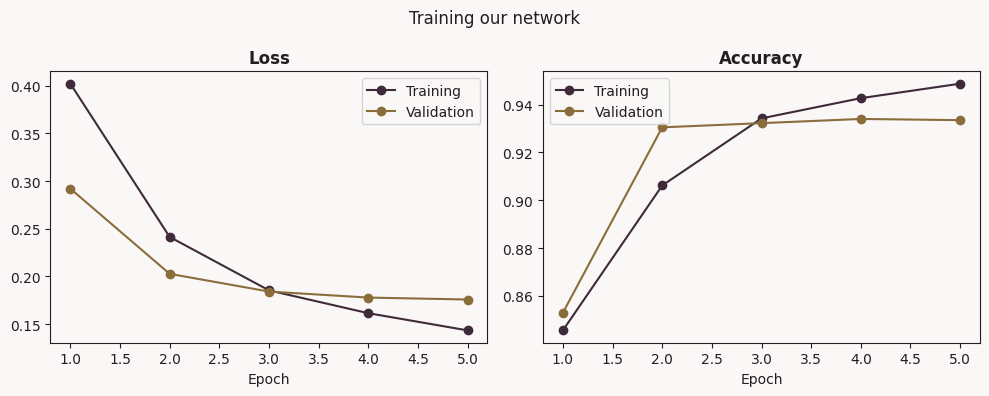

In [51]:
EPOCHS = 5

start = time.time()
history = model.fit(X_train, y_train, validation_data=(X_val, y_val),
                    epochs=EPOCHS, batch_size=64, verbose=2)
train_seconds = time.time() - start
print(f"\nTraining took {train_seconds:.0f} seconds.")

def plot_history(history, title):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    epochs = range(1, len(history.history["loss"]) + 1)
    for ax, metric, label in [(axes[0], "loss", "Loss"), (axes[1], "accuracy", "Accuracy")]:
        ax.plot(epochs, history.history[metric], marker="o", color=THEME["plum"], label="Training")
        ax.plot(epochs, history.history[f"val_{metric}"], marker="o", color=THEME["bronze"], label="Validation")
        ax.set_xlabel("Epoch")
        ax.set_title(label)
        ax.legend()
    plt.suptitle(title)
    plt.tight_layout()
    plt.show()

plot_history(history, "Training our network")

### See it for yourself: overfitting

`✏️ TINKER` Choose a network size, number of epochs, and dropout, then **run the cell below**. Each run trains a new network from scratch, which takes a few seconds. *This doesn't change the model used in the rest of the notebook.*

For example, try a bigger or a smaller network network, fewer or more epochs, and a different tropout rated

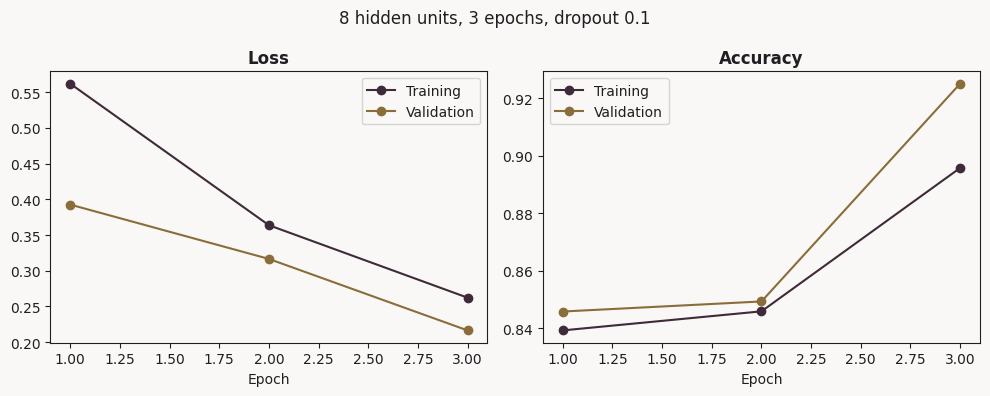

Parameters: 160,145
Final validation accuracy: 92.5%


In [52]:
# ✏️ TINKER: change these values, then re-run this cell
hidden_units = 8    # try 8 or 128
epochs = 3           # try 3 or 20
dropout = 0.1        # try 0.5 or 0.8

keras.utils.set_random_seed(SEED)
tinker_model = build_model(hidden_units=hidden_units, dropout=dropout)
tinker_history = tinker_model.fit(X_train, y_train, validation_data=(X_val, y_val),
                                  epochs=epochs, batch_size=64, verbose=0)

plot_history(tinker_history, f"{hidden_units} hidden units, {epochs} epochs, dropout {dropout:.1f}")
print(f"Parameters: {tinker_model.count_params():,}")
print(f"Final validation accuracy: {tinker_history.history['val_accuracy'][-1]:.1%}")

`✏️ QUESTION` **When the training loss keeps going down but the validation loss starts going up, what is the network doing? What did dropout change?**

The network is overfitting. Gradient descent keeps reducing the error on the training data, so the network starts memorizing details of specific bios, including noise, instead of learning general patterns.

As a result, it performs worse on bios it has not seen. Dropout randomly switches off some values during training, so the network cannot rely too heavily on a few specific words or units.

In my test, with 128 hidden units and 20 epochs, validation loss started rising around epoch 2 ~ 3 while training loss kept falling. With dropout 0.5, validation loss stayed lower, and the final validation accuracy was 91.1%, compared with 90.1% without dropout.

---
## 7. Model Evaluation

Let's check our network on the validation set, starting with accuracy.

In [53]:
val_probs = model.predict(X_val, verbose=0).ravel()
results = val_df[["bio", "profession", "gender", "label"]].copy()
results["prob"] = val_probs
results["predicted"] = (val_probs >= 0.5).astype(int)

overall_acc = accuracy_score(results["label"], results["predicted"])
always_no = 1 - results["label"].mean()
print(f"Validation accuracy: {overall_acc:.1%}")
print(f"For comparison, a 'model' that always says 'not a {TARGET}' would score {always_no:.1%}.")

Validation accuracy: 93.3%
For comparison, a 'model' that always says 'not a surgeon' would score 84.6%.


Accuracy looks high. But as last week, accuracy doesn't tell us *who* the model gets wrong. The question that matters for the platform is **recall**: of all the real surgeons, how many does the model find? Let's calculate it separately for women and men.

,real surgeons,Accuracy,Recall (equal opportunity),False positive rate,Precision (predictive parity)
group,,,,,
Female,84,0.973,0.524,0.007,0.759
Male,533,0.894,0.711,0.040,0.867


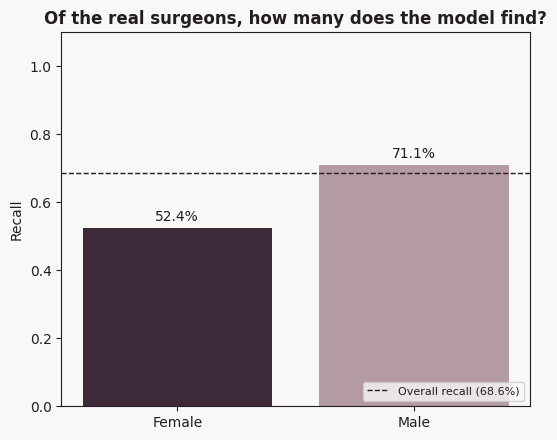

In [54]:
def group_metrics(results, attribute="gender"):
    rows = []
    for group in sorted(results[attribute].unique()):
        subset = results[results[attribute] == group]
        actual_pos = subset[subset["label"] == 1]
        actual_neg = subset[subset["label"] == 0]
        predicted_pos = subset[subset["predicted"] == 1]
        rows.append({
            "group": group,
            f"real {TARGET}s": len(actual_pos),
            "Accuracy": accuracy_score(subset["label"], subset["predicted"]),
            "Recall (equal opportunity)": actual_pos["predicted"].mean() if len(actual_pos) else float("nan"),
            "False positive rate": actual_neg["predicted"].mean() if len(actual_neg) else float("nan"),
            "Precision (predictive parity)": predicted_pos["label"].mean() if len(predicted_pos) else float("nan"),
        })
    return pd.DataFrame(rows).set_index("group")

gender_metrics = group_metrics(results)
display(gender_metrics.round(3))

overall_recall = recall_score(results["label"], results["predicted"])
recalls = gender_metrics["Recall (equal opportunity)"]
plt.figure(figsize=(5.5, 4.5))
plt.bar(recalls.index, recalls.values, color=PALETTE[:len(recalls)])
plt.axhline(overall_recall, linestyle="--", color=THEME["text"], linewidth=1,
            label=f"Overall recall ({overall_recall:.1%})")
for i, r in enumerate(recalls.values):
    plt.text(i, r + 0.02, f"{r:.1%}", ha="center")
plt.ylim(0, 1.1)
plt.ylabel("Recall")
plt.title(f"Of the real {TARGET}s, how many does the model find?")
plt.legend(loc="lower right", fontsize=8)
plt.tight_layout()
plt.show()

`✏️ QUESTION` **Compare the accuracy and the recall for women and men. What would a woman surgeon using this platform experience?**

Accuracy is similar for women and men (0.973% vs. 0.894%), but recall is lower for women (0.524% vs. 0.711%). This means the model finds men surgeons more reliably than women surgeons.

Accuracy hides this gap because most bios are not surgeons and women surgeons are a small group.

A woman surgeon on this platform would be more likely to be not tagged as a surgeon, so she might not see relevant job ads and would not know why.

Because there are only 84 women surgeons in the validation set, compared with 533 men, women's recall can shift noticeably with just a few people.
This means the group that the model treats worst is also the one we have the least evidence about


> Note: the number of real surgeons who are women is small (see the table), so their recall moves a lot with just a few people. That's a problem in itself: the group the model treats worst is also the group we have the least evidence about.

---
## 8. Opening the Black Box

We can't read 160,000 parameters. But we can run experiments on the model, the way you'd test any black box: change the input and watch the output.

### Experiment 1: swap the pronouns

For every real surgeon in the validation set, we rewrite the bio with the pronouns swapped (*she → he, her → his*, and the other way round). Nothing else changes. If the model only looked at the work people do, the results would stay the same.

He says his patients trust him, and he trusts them. 



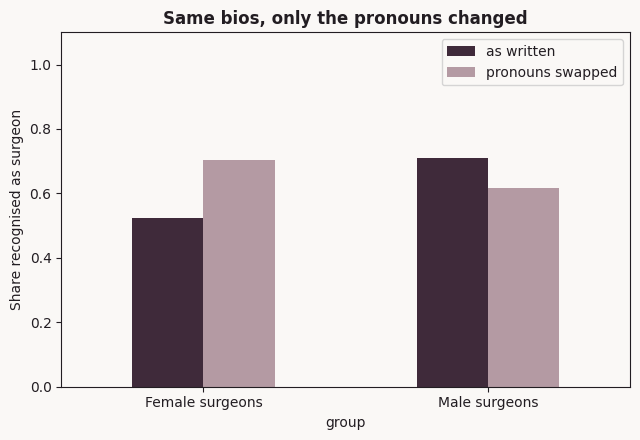

,as written,pronouns swapped,people
group,,,
Female surgeons,0.524,0.702,84
Male surgeons,0.711,0.615,533


In [55]:
SWAP = {"she": "he", "her": "his", "hers": "his", "herself": "himself", "ms": "mr", "mrs": "mr", "miss": "mr",
        "he": "she", "his": "her", "him": "her", "himself": "herself", "mr": "ms"}

NOT_A_NOUN = {"and", "or", "to", "in", "on", "at", "for", "with", "as", "from", "by", "that", "the", "a", "an", "is", "was"}

def swap_pronouns(text):
    # "her" can mean "his" (her patients) or "him" (trust her), so we check the next word
    def replace(match):
        word = match.group(1)
        following = match.group(2) or ""
        new = SWAP[word.lower()]
        if word.lower() == "her" and (not following or following.lower() in NOT_A_NOUN):
            new = "him"
        new = new.capitalize() if word[0].isupper() else new
        return new + match.group(0)[len(word):]
    pattern = r"\b(" + "|".join(SWAP) + r")\b(?=(?:\s+(\w+))?)"
    return re.sub(pattern, replace, text, flags=re.IGNORECASE)

print(swap_pronouns("She says her patients trust her, and she trusts them."), "\n")

swap_rows = []
for gender in ["Female", "Male"]:
    group = results[(results["label"] == 1) & (results["gender"] == gender)]
    swapped = np.array([swap_pronouns(t) for t in group["bio"]], dtype=object)
    swapped_found = (model.predict(swapped, verbose=0).ravel() >= 0.5).mean()
    swap_rows.append({"group": f"{gender} {TARGET}s", "as written": group["predicted"].mean(),
                      "pronouns swapped": swapped_found, "people": len(group)})
swap_df = pd.DataFrame(swap_rows).set_index("group")

ax = swap_df[["as written", "pronouns swapped"]].plot(kind="bar", color=[THEME["plum"], THEME["mauve"]],
                                                       figsize=(6.5, 4.5), rot=0)
ax.set_ylim(0, 1.1)
ax.set_ylabel(f"Share recognised as {TARGET}")
ax.set_title("Same bios, only the pronouns changed")
plt.tight_layout()
plt.show()
display(swap_df.round(3))

`✏️ QUESTION` **What happens to women surgeons' bios when the pronouns are swapped? And to men's? What has the network learned about the word "she"?**

When the pronouns in women surgeons' bios are changed from “she” to “he,” the share recognized as surgeons rises from 0.524% to 0.702%.

When men surgeons' bios are changed from “he” to “she,” the share falls from 0.711% to 0.615%.

Nothing else in the bios changed, so the difference comes only from the pronouns. This shows that the network has learned to treat “she” as evidence against being a surgeon and “he” as evidence for it.

Because most surgeons in the training data are men, backpropagation strengthened this association as a **shortcut** for reducing error, even though pronouns say nothing about a person's surgical work.



### Experiment 2: which words matter?

We can't ask the network why it made a decision, but we can test it word by word. For every real surgeon's bio in the validation set, we remove one word at a time, re-run the model, and record how much the prediction changes. Averaged over hundreds of bios, this shows which words the network relies on.

This takes a few seconds.

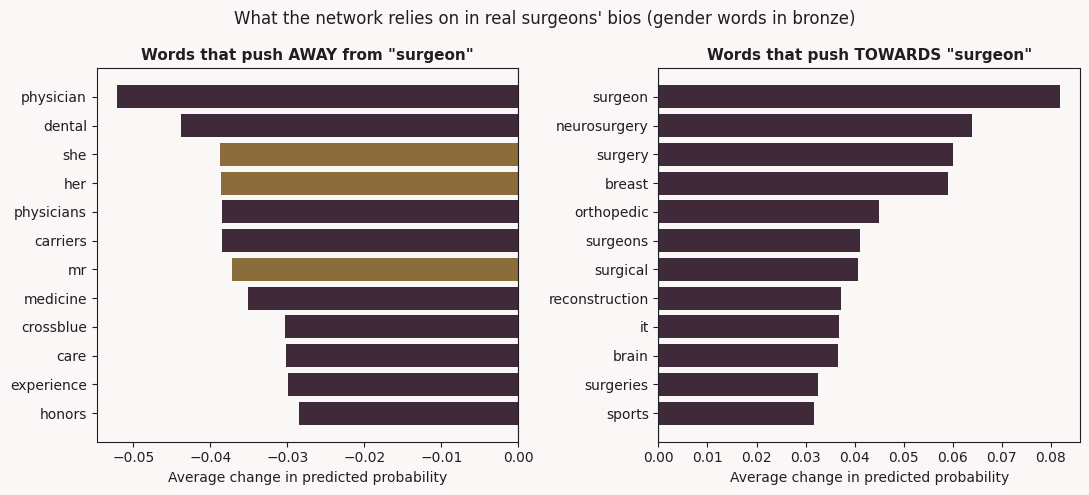

Gender words:


,mean,count
word,,
she,-0.0387,129
her,-0.0387,62
he,0.0060,962
his,-0.0055,437


In [62]:
GENDER_HIGHLIGHT = {"she", "her", "hers", "he", "his", "him", "mr", "ms", "mrs"}

def word_effects(m, bios, min_count=15):
    variants, owners = [], []
    for k, bio in enumerate(bios):
        words = bio.split()
        variants.append(bio); owners.append((k, None))
        for i in range(len(words)):
            variants.append(" ".join(words[:i] + words[i + 1:]))
            owners.append((k, re.sub(r"[^\w']", "", words[i].lower())))
    probs = m.predict(np.array(variants, dtype=object), verbose=0, batch_size=512).ravel()
    full, rows = {}, []
    for (k, word), p in zip(owners, probs):
        if word is None:
            full[k] = p
        else:
            rows.append((word, full[k] - p))   # positive = this word pushed towards TARGET
    effects = pd.DataFrame(rows, columns=["word", "effect"]).groupby("word")["effect"].agg(["mean", "count"])
    return effects[effects["count"] >= min_count].sort_values("mean")

target_bios = results.loc[results["label"] == 1, "bio"]
effects = word_effects(model, target_bios.sample(min(600, len(target_bios)), random_state=SEED).tolist())

fig, axes = plt.subplots(1, 2, figsize=(11, 5))
for ax, part, title in [(axes[0], effects.head(12)[::-1], f'Words that push AWAY from "{TARGET}"'),
                        (axes[1], effects.tail(12), f'Words that push TOWARDS "{TARGET}"')]:
    colors = [THEME["bronze"] if w in GENDER_HIGHLIGHT else THEME["plum"] for w in part.index]
    ax.barh(part.index, part["mean"], color=colors)
    ax.axvline(0, color=THEME["text"], linewidth=0.8)
    ax.set_title(title, fontsize=11)
    ax.set_xlabel("Average change in predicted probability")
plt.suptitle(f"What the network relies on in real {TARGET}s' bios (gender words in bronze)")
plt.tight_layout()
plt.show()

print("Gender words:")
display(effects.loc[[w for w in ["she", "her", "he", "his"] if w in effects.index]].round(4))

### Experiment 3: Where did the words end up?

In section 4, each word got a list of 16 numbers that started out random. Training has now adjusted them. We can't draw 16 dimensions, so we squash them down to 2 with **Principle Component Analysis**, a dimensionality reduction  method (unsupervised learning) that keeps the directions where the words differ most. Words the network treats similarly should end up close together.

Grey dots are the 1,000 most common words. The labelled words are ones we picked: work words in plum, gender words in bronze.

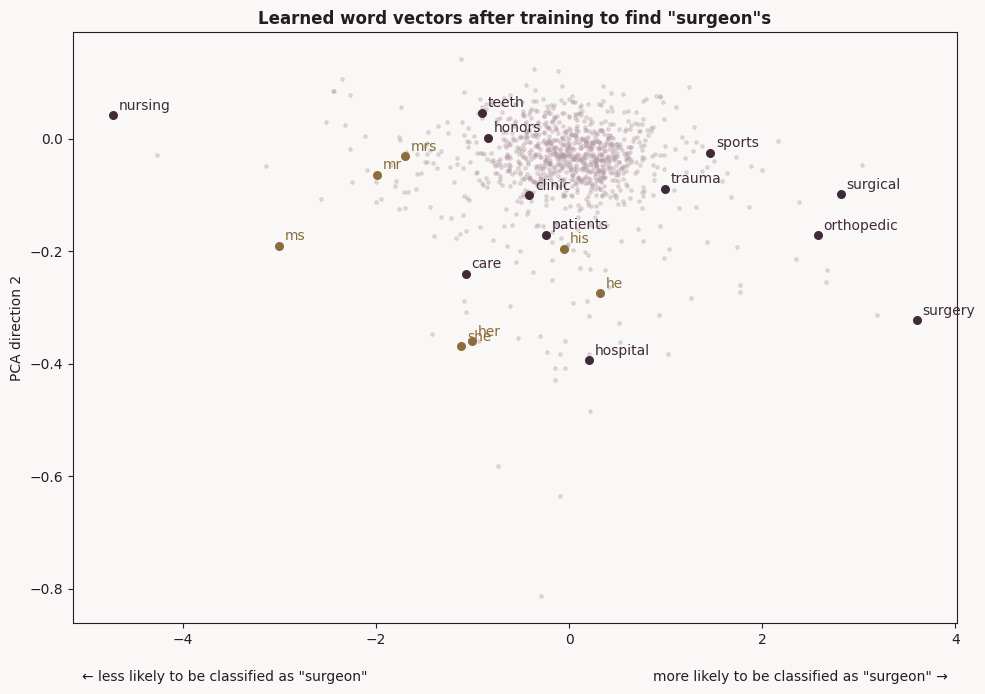

In [57]:
from sklearn.decomposition import PCA

WORDS_TO_SHOW = ["surgery", "surgical", "honors", "orthopedic", "trauma", "hospital",
                 "patients", "nursing", "care", "sports", "teeth", "clinic"]   # ✏️ TINKER: add your own words
GENDER_WORDS = ["she", "her", "he", "his", "mr", "ms", "mrs"]

embedding_layer = next(l for l in model.layers if isinstance(l, keras.layers.Embedding))
vectors = embedding_layer.get_weights()[0][:len(vocab)]   # one row per word in the vocabulary
words = vocab[2:]                                          # skip padding and unknown-word IDs
xy = PCA(n_components=2, random_state=SEED).fit_transform(vectors[2:])

# Which way is "surgeon"? Ask the model about each word on its own, then flip the x-axis if needed
word_probs = model.predict(np.array(words, dtype=object), verbose=0, batch_size=512).ravel()
corr = np.corrcoef(xy[:, 0], word_probs)[0, 1]
if corr < 0:
    xy[:, 0] = -xy[:, 0]

word_pos = {w: xy[i] for i, w in enumerate(words)}

plt.figure(figsize=(10, 7))
common = xy[:1000]   # vocabulary is sorted by frequency
plt.scatter(common[:, 0], common[:, 1], s=6, alpha=0.3, color=THEME["mauve"])
for word_list, color in [(WORDS_TO_SHOW, THEME["plum"]), (GENDER_WORDS, THEME["bronze"])]:
    for w in word_list:
        if w in word_pos:
            x, y = word_pos[w]
            plt.scatter(x, y, s=30, color=color)
            plt.annotate(w, (x, y), xytext=(4, 4), textcoords="offset points", color=color, fontsize=10)
        else:
            print(f'"{w}" is not in the vocabulary')

ax = plt.gca()
ax.text(0.01, -0.08, f'← less likely to be classified as "{TARGET}"', transform=ax.transAxes,
        ha="left", va="top", fontsize=10, color=THEME["text"])
ax.text(0.99, -0.08, f'more likely to be classified as "{TARGET}" →', transform=ax.transAxes,
        ha="right", va="top", fontsize=10, color=THEME["text"])
plt.ylabel("PCA direction 2")
plt.title(f'Learned word vectors after training to find "{TARGET}"s')
plt.tight_layout()
plt.show()

`✏️ QUESTION` **Look at the words that push *away* from "surgeon". Why do words unrelated to someone's professional skills have such effect?**

Gender words such as “she” and “her” push away from “surgeon,” alongside job-related words like “nursing” and “teeth.” Pronouns say nothing about skill, but the network learns whatever reduces prediction error, not what is relevant to the job. Because most surgeons in the training data are men, “she” and “her” appear more often in other medical bios, so backpropagation turned them into signals against “surgeon.”

The network turned a statistical pattern into a decision rule.

## 9. Training a "genderless" model

When Amazon found that its CV screener penalised words like "women's", it edited the system to ignore those words. Let's try the same thing: remove pronouns and titles from every bio, then train a new network on the cleaned text.

`✏️ TINKER` You can add more words to `GENDER_WORDS`, then re-run this cell.

Before: She graduated with honors from University Of Cincinnati College Of Medicine in 1978. Having more than 38 years of diverse experiences, [...]
After:  graduated with honors from University Of Cincinnati College Of Medicine in 1978. Having more than 38 years of diverse experiences, especially in [...] 



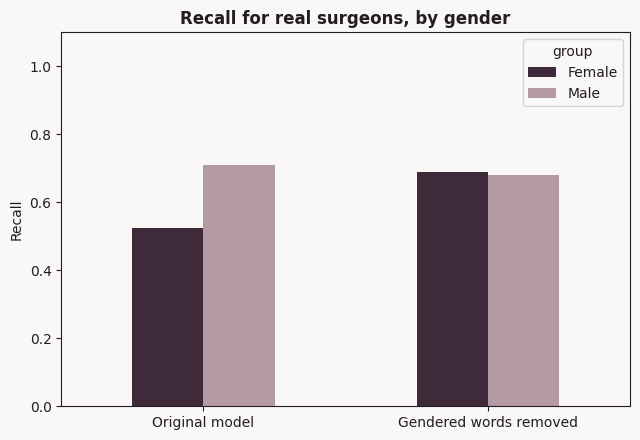

,accuracy,recall (women),recall (men),gap
Original model,0.934,0.524,0.711,0.187
Gendered words removed,0.932,0.690,0.679,0.011


In [58]:
GENDER_WORDS = ["he", "she", "his", "her", "hers", "him", "himself", "herself", "mr", "mrs", "ms", "miss"]

def scrub(texts):
    pattern = r"\b(" + "|".join(GENDER_WORDS) + r")\b"
    return np.array([re.sub(pattern, " ", t, flags=re.IGNORECASE) for t in texts], dtype=object)

X_train_s, X_val_s, X_test_s = scrub(X_train), scrub(X_val), scrub(X_test)
print("Before:", textwrap.shorten(X_val[0], 150))
print("After: ", textwrap.shorten(X_val_s[0], 150), "\n")

keras.utils.set_random_seed(SEED)
scrubbed_model = build_model()
scrubbed_model.fit(X_train_s, y_train, validation_data=(X_val_s, y_val), epochs=EPOCHS, batch_size=64, verbose=0)

results_s = results.copy()
results_s["predicted"] = (scrubbed_model.predict(X_val_s, verbose=0).ravel() >= 0.5).astype(int)
scrubbed_metrics = group_metrics(results_s)

compare = pd.DataFrame({
    "Original model": gender_metrics["Recall (equal opportunity)"],
    "Gendered words removed": scrubbed_metrics["Recall (equal opportunity)"],
}).T
ax = compare.plot(kind="bar", color=PALETTE[:2], figsize=(6.5, 4.5), rot=0)
ax.set_ylim(0, 1.1)
ax.set_ylabel("Recall")
ax.set_title(f"Recall for real {TARGET}s, by gender")
plt.tight_layout()
plt.show()

summary = pd.DataFrame({
    "accuracy": [overall_acc, accuracy_score(results_s["label"], results_s["predicted"])],
    "recall (women)": compare["Female"].values,
    "recall (men)": compare["Male"].values,
}, index=compare.index)
summary["gap"] = (summary["recall (men)"] - summary["recall (women)"]).abs()
display(summary.round(3))

In [59]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score

tr, va = (train_df["label"] == 1).values, (val_df["label"] == 1).values
g_train = (train_df["gender"] == "Female").values[tr]
g_val = (val_df["gender"] == "Female").values[va]

tfidf = TfidfVectorizer(max_features=5000, min_df=3)
probe = LogisticRegression(max_iter=1000, class_weight="balanced")
probe.fit(tfidf.fit_transform(X_train_s[tr]), g_train)
score = balanced_accuracy_score(g_val, probe.predict(tfidf.transform(X_val_s[va])))
print(f"Guessing gender from scrubbed {TARGET} bios: {score:.0%} (50% = pure guessing)")

coefs = pd.Series(probe.coef_[0], index=tfidf.get_feature_names_out()).sort_values()
display(pd.DataFrame({"words suggesting a man": coefs.head(12).index,
                      "words suggesting a woman": coefs.tail(12).index[::-1]}))

Guessing gender from scrubbed surgeon bios: 62% (50% = pure guessing)


,words suggesting a man,words suggesting a woman
0,orthopaedic,breast
1,orthopedic,dental
2,hospital,mbbs
3,spine,general
4,replacement,mumbai
5,than,women
6,surgeons,cigna
7,spinal,2011
8,sports,glaucoma
9,state,york


---
## 10. Deploy: try the model yourself

Now imagine the platform is live. Type or paste a bio, and see what each model decides. Words highlighted in **dark** pushed the model towards "surgeon"; words in **light** pushed it away. The highlighting works like the experiments above: the model is re-run with each word removed in turn, and we measure how much the prediction changes.

`✏️ TINKER` Try the example below with both models. Then change the pronouns, add a first name, or describe the same work in different words.

In [63]:
EXAMPLE_BIO = ("She completed her training at Johns Hopkins and joined the hospital in 2012. "
               "Her clinical interests include breast cancer and hernia repair.")

models = {"Original model": (model, lambda t: t), "Gendered words removed": (scrubbed_model, lambda t: scrub([t])[0])}

def predict_one(m, text):
    return float(m.predict(np.array([text], dtype=object), verbose=0)[0, 0])

def highlight(m, prep, text):
    words = text.split()
    variants = [prep(text)] + [prep(" ".join(words[:i] + words[i + 1:])) for i in range(len(words))]
    probs = m.predict(np.array(variants, dtype=object), verbose=0).ravel()
    effect = probs[0] - probs[1:]                   # how much each word raised the probability
    scale = max(np.abs(effect).max(), 1e-6)
    spans = []
    for word, e in zip(words, effect):
        rgb = (63, 42, 58) if e > 0 else (180, 154, 163)       # plum = towards, mauve = away
        alpha = round(float(min(abs(e) / scale, 1) * 0.85), 2)
        text_color = "white" if (e > 0 and alpha > 0.45) else THEME["text"]
        spans.append(f'<span style="background: rgba{rgb + (alpha,)}; color: {text_color}; '
                     f'padding: 2px 3px; border-radius: 3px;">{word}</span>')
    return probs[0], " ".join(spans)

def try_bio(model_name, bio):
    m, prep = models[model_name]
    prob, html = highlight(m, prep, bio)
    decision = f"✅ tagged as {TARGET}" if prob >= 0.5 else f"❌ not tagged as {TARGET}"
    swapped_prob = predict_one(m, prep(swap_pronouns(bio)))
    display(show_html(f"<p><b>{model_name}:</b> {decision} ({prob:.0%})</p>"
                      f"<p style='line-height: 2;'>{html}</p>"
                      f"<p>Same bio with the pronouns swapped: {swapped_prob:.0%}</p>"))

interact(
    try_bio,
    model_name=Dropdown(options=list(models), description="Model"),
    bio=Textarea(value=EXAMPLE_BIO, description="Bio", continuous_update=False,
                 layout=Layout(width="95%", height="110px")),
);

interactive(children=(Dropdown(description='Model', options=('Original model', 'Gendered words removed'), valu…

`✏️ QUESTION` **Find a bio where the decision changes when only the pronouns change. Did the same thing happen with the model trained without gendered words? What else could you change to make a difference?**


With the example bio, the original model did not tag the person as a surgeon (39%), but swapping only the pronouns changed the result to 90%. “She” and “her” pushed away from “surgeon,” while “breast” and “repair” pushed toward it. The model without gendered words tagged the bio as a surgeon (87%), and swapping pronouns had no effect, since they are removed before prediction.

However, other words, such as first names, “mother,” “women’s health,” or describing the same work differently, could still change the result, because they are indirectly linked to gender.

---
## 11. Final check on the test set

Until now, every decision used the **validation** set. Pick the model you would actually deploy, and run this cell **once**. Don't go back and tune things after seeing the result.

In [64]:
FINAL_MODEL = "Gendered words removed"   # ✏️ FILL IN: "Original model" or "Gendered words removed"

final, prep_test = (model, X_test) if FINAL_MODEL == "Original model" else (scrubbed_model, X_test_s)
test_results = test_df[["gender", "label"]].copy()
test_results["predicted"] = (final.predict(prep_test, verbose=0).ravel() >= 0.5).astype(int)
test_metrics = group_metrics(test_results)

print(f"Final model: {FINAL_MODEL}")
print(f"Test accuracy: {accuracy_score(test_results['label'], test_results['predicted']):.1%}")
display(test_metrics[[f"real {TARGET}s", "Recall (equal opportunity)"]].round(3))

Final model: Gendered words removed
Test accuracy: 93.2%


,real surgeons,Recall (equal opportunity)
group,,
Female,127,0.598
Male,645,0.684


`✏️ QUESTION` **Why did you choose this model? Do the test results match the validation results? Would you let the platform use it, and if so, with what safeguards?**


I chose the model without gendered words because its decisions did not change when only the pronouns were swapped.

On the test set, it reached 93.2% accuracy, but recall was still lower for women surgeons (59.8%) than for men (68.4%), consistent with the validation results (69.0% vs. 67.9%).

Removing pronouns reduced their direct effect but did not close the gap, likely because other words still carry gender information.

With only 127 women surgeons in the test set, their results are also less certain. I would allow its use only with safeguards: monitoring recall by gender, letting users correct their tags, and using tags only to suggest job ads, not to exclude anyone.

---
## 12. Reflection: what does it cost?

`✏️ QUESTION` **The people in this dataset wrote their bios for their own websites, not to train AI. Their gender was guessed from pronouns, and people who use other pronouns were left out. Who else is affected by these choices, and who should have a say?**

I think the effects reach beyond the people whose bios were used. People who use other pronouns were left out, so the model may not work well for them.

Platform users, such as women surgeons, may see fewer relevant job ads, and employers may miss qualified candidates.

Because all of these groups bear the consequences, it seems reasonable that they should have some say, together with the platform and regulators, for example through consent, the option to correct labels, and review before deployment.

>

`✏️ QUESTION` **What ethical problems does deep learning introduces or reinforces, compared to machine learning?**

The main difference, in my view, is who chooses the features.

In machine learning, people select them, so possible sources of bias are at least visible.

In deep learning, the network learns its own features through backpropagation, so it may pick up proxies for gender that no one intended. This also makes decisions harder to explain.

As this assignment suggested, removing obvious words may not be enough, since the network can find similar signals in other words.

Deep learning may also reinforce existing concerns, such as relying on large datasets collected without clear consent and requiring significant computing resources.

>

`✏️ TINKER` (optional) Go back to section 3, set `TARGET = "nurse"`, and choose "Runtime > Run all". Which group does the model now overlook?

---
## Before you submit: a quick honesty check

Note briefly:
1. Did you use an AI tool (ChatGPT, Claude, Copilot, etc.) to write, explain, or fix any code in this notebook? If so, which parts?
2. For the parts you didn't write yourself — how confident are you that you understand what that code is doing, and why? What's one line or step you're still unsure about?

> **I used Claude to understand the questions, interpret the results and draft my answers, and I revised them in my own words. It was highy difficult.**

There's no penalty for using AI tools here — this course is partly *about* how we relate to AI assistance, so answer honestly. Your grade is based on your understanding (shown in the reflections above), not on whether you typed every line yourself.

## Submission checklist

Before you submit, check that you have:
- [ ] Run every cell in order, top to bottom (no errors, or errors you've explained)
- [ ] Answered every "Your answer" reflection prompt in your own words
- [ ] Filled in every `# ✏️ FILL IN` marker with a real choice, not left as a placeholder
- [ ] Tried at least one of the tinkering points and can say what changed
- [ ] Completed the honesty check above

**Grading (applies equally whether you're on the 🟢 or 🔵 path):**
| Criterion | Weight |
|---|---|
| Conceptual understanding (explained in your own words) | 40% |
| Evidence of experimentation (tried a variation, reported what changed) | 25% |
| Critical/ethical reflection | 25% |
| Clarity of submission | 10% |